# WP5 – Database Export and Documentation

Reconstructed from the saved code copy. Not executed against project data. Place in `WP5/` and run from that directory.

Inputs: WP3 normalised CSV and mapping JSON files, and WP4 prompt JSON. Results must be regenerated after WP2/WP3 revisions.

Reconstruction fixes: missing closing parenthesis and a repeated data reload that discarded a derived column. Remaining issues are listed at the end.


## Database Export (Parquet)


In [1]:
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import json
import os
# load normalised dataset from WP3
df = pd.read_csv(
    '../data/ctrate_train_normalised.csv',
    dtype={'patient_id': 'string', 'study_id': 'string'}
)
print(f"Loaded normalised dataset: {df.shape}")
# ---- Select relevant columns for LLM querying ----
# based on WP4 metadata requirements analysis
TEXT_COLS = [
    'Findings_EN',
    'Findings_EN_norm',       # normalised version from WP3
    'Impressions_EN',
    'Impressions_EN_norm',    # normalised version from WP3
    'ClinicalInformation_EN',
]
PATIENT_COLS = [
    'VolumeName',
    'patient_id',
    'PatientAge',
    'PatientSex',
]
STUDY_COLS = [
    'StudyDate',
    'study_id'
]
TECHNICAL_COLS = [
    'Manufacturer',
    'ManufacturerModelName',
    'SeriesDescription',
    'ConvolutionKernel',
    'SliceThickness',
    'CTDIvol',
    'NumberofSlices',
]

# WP2 style columns
STYLE_COLS = ['style_id', 'trachea_phrase']
# combine all relevant columns
EXPORT_COLS = PATIENT_COLS + STUDY_COLS + TEXT_COLS + TECHNICAL_COLS + STYLE_COLS
# Report requested columns that are missing
missing_cols = [c for c in EXPORT_COLS if c not in df.columns]

if missing_cols:
    print("Requested columns missing from the dataset:")
    for column in missing_cols:
        print(f"  - {column}")

EXPORT_COLS = [c for c in EXPORT_COLS if c in df.columns]
required_cols = [
    'VolumeName',
    'patient_id',
    'study_id',
    'StudyDate',
    'Findings_EN',
    'Findings_EN_norm',
    'Impressions_EN',
    'PatientAge',
    'Impressions_EN_norm',
    'style_id',
    'trachea_phrase',
]

missing_required = [
    column for column in required_cols
    if column not in df.columns
]

if missing_required:
    raise ValueError(
        f"Required export columns are missing: {missing_required}"
    )
df_export = df[EXPORT_COLS].copy()
# Check study identifiers before export
id_cols = ['patient_id', 'study_id']

invalid_ids = (
    df_export[id_cols].isna().any(axis=1)
    | df_export[id_cols].apply(
        lambda column: column.str.strip().eq('')
    ).any(axis=1)
)

if invalid_ids.any():
    raise ValueError("Missing or blank patient/study identifiers.")

if df_export.duplicated(subset=id_cols).any():
    raise ValueError("Multiple rows found for the same patient and study.")
print(f"\nExport columns ({len(EXPORT_COLS)}):")
for group, cols in [
    ('Patient',   PATIENT_COLS),
    ('Study',     STUDY_COLS),
    ('Text',      TEXT_COLS),
    ('Technical', TECHNICAL_COLS),
    ('Style',     STYLE_COLS),
]:
    available = [c for c in cols if c in df.columns]
    print(f"  {group:12s}: {available}")
# ---- Data type optimisation ----
# convert StudyDate to datetime
date_raw = df_export['StudyDate'].astype('string').str.strip()

df_export['StudyDate'] = pd.to_datetime(
    date_raw,
    format='%Y-%m-%d',
    errors='coerce'
)

invalid_dates = (
    date_raw.notna()
    & date_raw.ne('')
    & df_export['StudyDate'].isna()
)

print(f"Dates that could not be parsed: {invalid_dates.sum()}")

if invalid_dates.any():
    print(date_raw[invalid_dates].head())
    raise ValueError("Review unparsed StudyDate values before exporting.")
# convert PatientAge to numeric
df_export['PatientAge_num'] = pd.to_numeric(
    df_export['PatientAge'].str.replace('Y', '').str.replace('y', ''),
    errors='coerce'
)
# ---- Export to Parquet ----
output_path = '../data/ctrate_llm_database.parquet'
df_export.to_parquet(
    output_path,
    engine='pyarrow',
    compression='snappy',   # fast compression, good for LLM pipelines
    index=False
)
# Export the same rows and columns as CSV
csv_export_path = '../data/ctrate_llm_database.csv'
df_export.to_csv(csv_export_path, index=False)

print(f"CSV export saved: {csv_export_path}")
# verify
df_verify = pd.read_parquet(output_path)
# Verify values, column order and data types after reloading
pd.testing.assert_frame_equal(
    df_export.reset_index(drop=True),
    df_verify.reset_index(drop=True),
    check_dtype=True
)

print("Parquet verification passed.")
# Check CSV structure, identifiers and report texts
df_csv = pd.read_csv(
    csv_export_path,
    dtype='string',
    keep_default_na=False
)

assert df_csv.shape == df_export.shape, "CSV dimensions differ."
assert df_csv.columns.tolist() == df_export.columns.tolist(), \
    "CSV columns differ."

for column in [
    'VolumeName', 'patient_id', 'study_id',
    'Findings_EN', 'Findings_EN_norm',
    'Impressions_EN', 'Impressions_EN_norm',
]:
    expected = df_export[column].astype('string').fillna('')
    pd.testing.assert_series_equal(
        expected.reset_index(drop=True),
        df_csv[column].reset_index(drop=True),
        check_names=False
    )

print("CSV structure, identifiers and report texts verified.")
file_size  = os.path.getsize(output_path) / 1024 / 1024
print(f"\nParquet export complete:")
print(f"  Path:       {output_path}")
print(f"  Rows:       {len(df_verify)}")
print(f"  Columns:    {len(df_verify.columns)}")
print(f"  File size:  {file_size:.1f} MB")
print(f"\nCompare to CSV:")
csv_size = os.path.getsize(csv_export_path) / 1024 / 1024
print(f"  CSV size:   {csv_size:.1f} MB")
print(f"  Reduction:  {(1 - file_size/csv_size)*100:.1f}%")


Loaded normalised dataset: (24113, 77)
Requested columns missing from the dataset:
  - SliceThickness

Export columns (19):
  Patient     : ['VolumeName', 'patient_id', 'PatientAge', 'PatientSex']
  Study       : ['StudyDate', 'study_id']
  Text        : ['Findings_EN', 'Findings_EN_norm', 'Impressions_EN', 'Impressions_EN_norm', 'ClinicalInformation_EN']
  Technical   : ['Manufacturer', 'ManufacturerModelName', 'SeriesDescription', 'ConvolutionKernel', 'CTDIvol', 'NumberofSlices']
  Style       : ['style_id', 'trachea_phrase']
Dates that could not be parsed: 0
CSV export saved: ../data/ctrate_llm_database.csv


/tmp/ipykernel_493138/1855631960.py:145: FutureWarning: Mismatched null-like values nan and None found. In a future version, pandas equality-testing functions (e.g. assert_frame_equal) will consider these not-matching and raise.
  pd.testing.assert_frame_equal(


Parquet verification passed.
CSV structure, identifiers and report texts verified.

Parquet export complete:
  Path:       ../data/ctrate_llm_database.parquet
  Rows:       24113
  Columns:    20
  File size:  22.2 MB

Compare to CSV:
  CSV size:   74.8 MB
  Reduction:  70.3%


## Imports and Setup


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import os
FIGURES_DIR = 'figures'
os.makedirs(FIGURES_DIR, exist_ok=True)
# load all relevant datasets
df_norm = pd.read_csv(
    '../data/ctrate_train_normalised.csv',
    dtype={'patient_id': 'string', 'study_id': 'string'}
)
df_llm     = pd.read_parquet('../data/ctrate_llm_database.parquet')
# load WP2 style registry from notebook output
# (style_id and trachea_phrase are already in df_norm)
# load WP3 mappings
with open('../WP3/lexical_mappings.json', 'r') as f:
    lexical_mappings = json.load(f)
with open('../WP3/spelling_corrections.json', 'r') as f:
    spelling_corrections = json.load(f)
# load WP4 prompt library
with open('../WP4/pacs_prompt_library.json', 'r') as f:
    prompt_library = json.load(f)
print("All datasets loaded.")
print(f"  Normalised dataset:  {df_norm.shape}")
print(f"  LLM database:        {df_llm.shape}")
print(f"  Lexical mappings:    {len(lexical_mappings)} groups")
print(f"  Spelling corrections:{len(spelling_corrections)}")
print(f"  Prompt library:      {len(prompt_library['prompts'])} prompts")


All datasets loaded.
  Normalised dataset:  (24113, 77)
  LLM database:        (24113, 20)
  Lexical mappings:    19 groups
  Spelling corrections:21
  Prompt library:      15 prompts


## Annotator Variability Summary


=== ANNOTATOR VARIABILITY (WP2) ===

Total reports:          24113
Distinct styles:        16
Trachea phrase groups:  8

Trachea phrase distribution:
  open_comma               :  8601 ( 35.7%)
  open_and                 :  5932 ( 24.6%)
  open_lumen               :  2464 ( 10.2%)
  open_main                :  1956 (  8.1%)
  cto                      :  1857 (  7.7%)
  no_trachea               :  1288 (  5.3%)
  midline                  :  1036 (  4.3%)
  other                    :   979 (  4.1%)

Style size statistics:
  Largest style:   4965 reports
  Smallest style:  318 reports
  Mean size:       1507 reports

Report length variation across styles:
  Max mean length: 285.2 words
  Min mean length: 110.7 words
  Overall std:     71.4 words

Dataset time range:
  From: 2016-01
  To:   2022-11


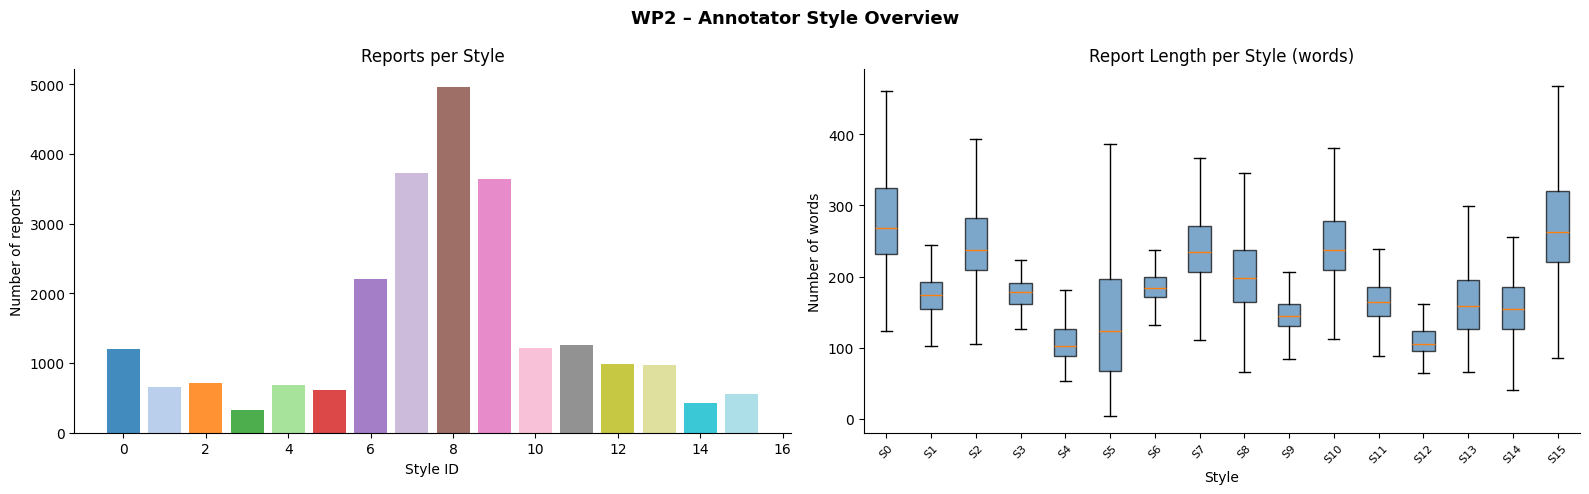

Saved: figures/wp5_annotator_variability.png


In [3]:
print("=== ANNOTATOR VARIABILITY (WP2) ===\n")
# style distribution
style_counts = df_norm['style_id'].value_counts().sort_index()
trachea_counts = df_norm['trachea_phrase'].value_counts()
print(f"Total reports:          {len(df_norm)}")
print(f"Distinct styles:        {df_norm['style_id'].nunique()}")
print(f"Trachea phrase groups:  {df_norm['trachea_phrase'].nunique()}")
print(f"\nTrachea phrase distribution:")
for phrase, count in trachea_counts.items():
    pct = count / len(df_norm) * 100
    print(f"  {phrase:25s}: {count:5d} ({pct:5.1f}%)")
print(f"\nStyle size statistics:")
print(f"  Largest style:   {style_counts.max()} reports")
print(f"  Smallest style:  {style_counts.min()} reports")
print(f"  Mean size:       {style_counts.mean():.0f} reports")
# report length per style
df_norm['findings_words'] = df_norm['Findings_EN'].fillna('').apply(
    lambda x: len(x.split())
)
length_stats = df_norm.groupby('style_id')['findings_words'].agg(
    ['mean', 'std']
).round(1)
print(f"\nReport length variation across styles:")
print(f"  Max mean length: {length_stats['mean'].max():.1f} words")
print(f"  Min mean length: {length_stats['mean'].min():.1f} words")
print(f"  Overall std:     {df_norm['findings_words'].std():.1f} words")
# temporal coverage
# Reuse the dates already checked during export
assert df_norm['VolumeName'].reset_index(drop=True).equals(
    df_export['VolumeName'].reset_index(drop=True)
), "Report order differs between summary and export."

df_norm['StudyDate'] = df_export['StudyDate'].to_numpy()
print(f"\nDataset time range:")
date_min = df_norm['StudyDate'].dropna().min()
date_max = df_norm['StudyDate'].dropna().max()
print(f"  From: {date_min.strftime('%Y-%m')}")
print(f"  To:   {date_max.strftime('%Y-%m')}")
# visualize style distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('WP2 – Annotator Style Overview', fontsize=13, fontweight='bold')
ax = axes[0]
colors = plt.cm.tab20(np.linspace(0, 1, len(style_counts)))
ax.bar(style_counts.index, style_counts.values, color=colors, alpha=0.85)
ax.set_title('Reports per Style')
ax.set_xlabel('Style ID')
ax.set_ylabel('Number of reports')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax = axes[1]
ax.boxplot(
    [df_norm[df_norm['style_id'] == sid]['findings_words'].values
     for sid in sorted(df_norm['style_id'].unique())],
    tick_labels=[f"S{sid}" for sid in sorted(df_norm['style_id'].unique())],
    patch_artist=True,
    showfliers=False,
    boxprops=dict(facecolor='steelblue', alpha=0.7)
)
ax.set_title('Report Length per Style (words)')
ax.set_xlabel('Style')
ax.set_ylabel('Number of words')
ax.tick_params(axis='x', rotation=45, labelsize=8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'wp5_annotator_variability.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {FIGURES_DIR}/wp5_annotator_variability.png")


## Standardisation Pipeline Summary


=== STANDARDISATION PIPELINE (WP3) ===

Lexical mapping groups:   19
Total variants mapped:    33
Spelling corrections:     21

Lexical mappings:
  ground_glass_opacity               : 6 variants (ground-glass opacity, ground glass opacity...)
  lung_opacity                       : 6 variants (infiltrate, infiltration...)
  consolidation                      : 1 variants (consolidations)
  consolidative                      : 2 variants (consolidating, consolidated)
  fibrotic                           : 2 variants (fibrotic changes, fibrotic sequelae)
  atelectasis                        : 1 variants (atelectases)
  atelectatic                        : 1 variants (atelectatic changes)
  calcification                      : 1 variants (calcifications)
  calcific                           : 2 variants (calcified, calcific changes)
  pleural_effusion                   : 2 variants (pleural fluid, pleural collection)
  pericardial_effusion               : 1 variants (pericardial fluid)
  

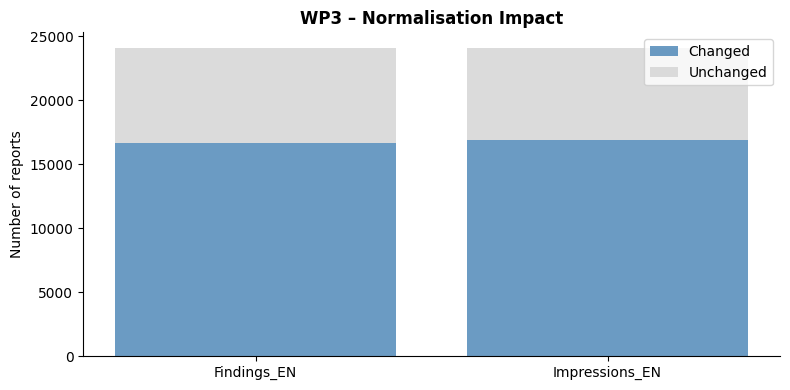

Saved: figures/wp5_normalisation_impact.png


In [4]:
print("=== STANDARDISATION PIPELINE (WP3) ===\n")
print(f"Lexical mapping groups:   {len(lexical_mappings)}")
total_variants = sum(len(v) for v in lexical_mappings.values())
print(f"Total variants mapped:    {total_variants}")
print(f"Spelling corrections:     {len(spelling_corrections)}")
print(f"\nLexical mappings:")
for canonical, variants in lexical_mappings.items():
    if variants:
        print(f"  {canonical:35s}: {len(variants)} variants "
              f"({', '.join(variants[:2])}{'...' if len(variants) > 2 else ''})")
print("\nManually selected spelling corrections:")
for wrong, correct in list(spelling_corrections.items())[:8]:
    print(f"  {wrong:30s} → {correct}")
if len(spelling_corrections) > 8:
    print(f"  ... and {len(spelling_corrections) - 8} more")
# normalisation impact
findings_changed = sum(
    1 for orig, norm in zip(
        df_norm['Findings_EN'].fillna(''),
        df_norm['Findings_EN_norm'].fillna('')
    )
    if orig.lower() != norm
)
impressions_changed = sum(
    1 for orig, norm in zip(
        df_norm['Impressions_EN'].fillna(''),
        df_norm['Impressions_EN_norm'].fillna('')
    )
    if orig.lower() != norm
)
print(f"\nNormalisation impact:")
print(f"  Findings changed:    {findings_changed:5d} ({findings_changed/len(df_norm)*100:.1f}%)")
print(f"  Impressions changed: {impressions_changed:5d} ({impressions_changed/len(df_norm)*100:.1f}%)")
# visualize
fig, ax = plt.subplots(figsize=(8, 4))
categories = ['Findings_EN', 'Impressions_EN']
changed    = [findings_changed, impressions_changed]
unchanged  = [len(df_norm) - c for c in changed]
ax.bar(categories, changed,   label='Changed',   color='steelblue', alpha=0.8)
ax.bar(categories, unchanged, label='Unchanged', color='lightgray',
       alpha=0.8, bottom=changed)
ax.set_title('WP3 – Normalisation Impact', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of reports')
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'wp5_normalisation_impact.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {FIGURES_DIR}/wp5_normalisation_impact.png")


## Recommended Query Formats


In [5]:
prompts = prompt_library['prompts']
print("=== RECOMMENDED QUERY FORMATS (WP4) ===\n")
print("Ordered by complexity (simple → complex)\n")
for complexity in ['simple', 'medium', 'complex']:
    subset = [p for p in prompts if p['complexity'] == complexity]
    print(f"--- {complexity.upper()} ({len(subset)} prompts) ---\n")
    for p in subset:
        print(f"  [{p['id']}] {p['category'].replace('_', ' ').title()}")
        print(f"  DE: {p['de']}")
        print(f"  EN: {p['en']}")
        print()
# key recommendations from interviews
print("=== KEY RECOMMENDATIONS FROM INTERVIEWS ===\n")
recommendations = [
    ("Completeness over precision",
     "Return all matches when ambiguous. Users prefer to filter manually "
     "rather than miss relevant results."),
    ("Support both German and English",
     "Clinicians may query in either language. "
     "The system should handle both."),
    ("Expand abbreviations",
     "GGO and LAP are rarely used in practice. "
     "The system should expand abbreviations but not assume them as input."),
    ("Separate non-synonymous terms",
     "Fibrosis ≠ scarring, emphysema ≠ bulla, "
     "lymphadenopathy ≠ enlarged lymph node. "
     "These must be treated as distinct concepts."),
    ("Accept fuzzy matching with control",
     "A slider/threshold for synonym expansion was suggested: "
     "users want control over how strictly the system searches."),
    ("Support longitudinal queries",
     "Tracking findings over time (e.g. nodule growth) "
     "is a high-value use case for research."),
]
for title, desc in recommendations:
    print(f"  ✓ {title}")
    print(f"    {desc}")
    print()


=== RECOMMENDED QUERY FORMATS (WP4) ===

Ordered by complexity (simple → complex)

--- SIMPLE (5 prompts) ---

  [Q01] Simple Finding
  DE: Zeige mir alle Patienten mit Pleuraerguss.
  EN: Show me all patients with pleural effusion.

  [Q02] Simple Finding
  DE: Erkenne alle Patienten mit soliden Lungenrundherden bis zu einer Größe von 1 cm.
  EN: Detect all patients with solid pulmonary nodules up to a size of 1 cm.

  [Q03] Simple Finding
  DE: Zeige mir alle Patienten mit Milchglastrübung.
  EN: Show me all patients with ground glass opacity.

  [Q06] Demographic Filter
  DE: Zeige mir alle CT-Untersuchungen von Patienten über 70 Jahren.
  EN: Show me all CT scans from patients older than 70 years.

  [Q08] Temporal Filter
  DE: Zeige mir alle Thorax-CTs mit Pleuraerguss aus den letzten 6 Monaten.
  EN: Show me all chest CTs with pleural effusion from the last 6 months.

--- MEDIUM (4 prompts) ---

  [Q04] Combined Finding
  DE: Ich möchte alle Patienten mit randständiger Kontrastmi

## Export Scope and Limitations

The export contains one retained reconstruction per study.
It is intended as an input for future text-based retrieval,
not as a validated retrieval system.

Technical metadata describe the retained reconstruction only.
Queries involving alternative reconstruction kernels may require
the volume-level WP1 dataset.

Missing metadata, provisional lexical mappings and unverified
style-group assignments limit downstream interpretation.
Patient identifiers alone do not establish that sufficient
follow-up examinations are available for longitudinal queries.

Original report texts are retained for comparison and review.

## System Integration Summary


In [6]:
print("=== HOW WP FINDINGS SUPPORT THE LLM SYSTEM ===\n")
summary = {
    "WP1 – Data Ingestion": {
        "output": "ctrate_train_combined.csv (47,119 rows, 66 columns)",
        "contribution": "Provides the raw dataset: free-text reports, "
                       "metadata and pathology labels linked via VolumeName."
    },
    "WP2 – Annotator Style Analysis": {
        "output": (
            f"{df_norm['style_id'].nunique()} exploratory style groups, "
            "with style_id assigned to each report"
        ),
        "contribution": (
            "Describes variation in report wording and structure. "
            "Groups are not verified annotator identities; "
            "their usefulness for retrieval remains to be evaluated."
        )
    },
    "WP3 – Standardisation": {
        "output": (
            "ctrate_train_normalised.csv, lexical_mappings.json, "
            "spelling_corrections.json"
        ),
        "contribution": (
            "Adds normalised text alongside the original reports "
            "using spelling, formatting and lexical rules. "
            "Some lexical mappings remain provisional; preservation "
            "of clinical meaning and retrieval benefits require evaluation."
        )
    },
    "WP4 – Clinician Interviews": {
        "output": (
            f"pacs_prompt_library.json "
            f"({len(prompt_library['prompts'])} interview-derived templates)"
        ),
        "contribution": (
            "Documents query examples, terminology preferences and "
            "ambiguity-handling requirements from two interviews. "
            "Query feasibility and retrieval performance require "
            "separate evaluation."
        )
    },
    "WP5 – Database Export": {
        "output": (
             f"ctrate_llm_database.parquet and ctrate_llm_database.csv "
             f"({len(df_llm)} rows, {len(df_llm.columns)} columns)"
            ),
        "contribution": (
            "Exports original and normalised report text, selected metadata "
            "and exploratory style-group assignments for future integration. "
            "Retrieval performance has not been evaluated."
        ),
    },
}
for wp, info in summary.items():
    print(f"{wp}")
    print(f"  Output:       {info['output']}")
    print(f"  Contribution: {info['contribution']}")
    print()
print("=== WP5 OUTPUT SUMMARY ===")
print(f"\nFinal database: ../data/ctrate_llm_database.parquet")
print(f"  {len(df_llm)} reports exported for future retrieval integration")
print(f"  {len(df_llm.columns)} columns")
actual_size_mb = os.path.getsize(output_path) / 1024 / 1024
print(f"  {actual_size_mb:.1f} MB (Parquet/Snappy)")

=== HOW WP FINDINGS SUPPORT THE LLM SYSTEM ===

WP1 – Data Ingestion
  Output:       ctrate_train_combined.csv (47,119 rows, 66 columns)
  Contribution: Provides the raw dataset: free-text reports, metadata and pathology labels linked via VolumeName.

WP2 – Annotator Style Analysis
  Output:       16 exploratory style groups, with style_id assigned to each report
  Contribution: Describes variation in report wording and structure. Groups are not verified annotator identities; their usefulness for retrieval remains to be evaluated.

WP3 – Standardisation
  Output:       ctrate_train_normalised.csv, lexical_mappings.json, spelling_corrections.json
  Contribution: Adds normalised text alongside the original reports using spelling, formatting and lexical rules. Some lexical mappings remain provisional; preservation of clinical meaning and retrieval benefits require evaluation.

WP4 – Clinician Interviews
  Output:       pacs_prompt_library.json (15 interview-derived templates)
  Contributi

## Pending Review

The export code now includes required-column checks, study-ID
checks, date parsing checks, CSV export and reload verification.

These checks have been prepared but not yet executed against
the revised project data.

Remaining tasks:
- Run WP1–WP5 in sequence and inspect all checks and outputs.
- Confirm the date format produced by the revised WP3 export.
- Decide whether the 18 abnormality labels belong in this export.
- Review the remaining terminology recommendations against
  the interview notes.
- Confirm that age values use years before interpreting PatientAge_num.
- Update the report using verified results.
